# Bagian B: Hasil Pemrosesan dan Model Gaussian Naïve Bayes
Melanjutkan **Bagian A** (pra-pemrosesan). Notebook ini membaca file hasil Bagian A, jadi bisa dijalankan sendiri selama file berikut ada:
`data/student_exam_performance.csv`, `data/data_latih_proses.csv`, `data/data_uji_proses.csv`.

| Bagian | Isi | Dipakai untuk laporan |
|---|---|---|
| 0 | Pengaturan | - |
| 6 | Hasil pemrosesan: 5 baris teratas/terbawah, ringkasan sebelum dan sesudah | Bab 6 |
| 7 | Model dan evaluasi: accuracy, precision, recall, F1, confusion matrix | Bab 7 |
| 7.7 - 7.8 | Analisis pendukung: pengaruh prior dan pengaruh skala | Pembahasan Bab 5.6 dan 5.9 |

**Aturan pemakaian data:** model **dilatih hanya dengan data latih** (sudah di-oversampling) dan **dievaluasi hanya dengan data uji** (distribusi asli, tidak disentuh). Data uji tidak dipakai untuk memilih atau menyetel apa pun.

## Bagian 0. Pengaturan

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, roc_auc_score)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# ---------- Pengaturan ----------
PATH_MENTAH = '../data/student_exam_performance.csv'
PATH_LATIH  = '../data/data_latih_proses.csv'
PATH_UJI    = '../data/data_uji_proses.csv'         # keluaran Bagian A
TARGET        = "pass_status"
KELAS_POSITIF = "Fail"          # kelas yang ingin dikenali (minoritas)
KELAS_LAIN    = "Pass"
RANDOM_STATE  = 42

FITUR = [
    "previous_exam_score", "previous_gpa", "attendance_percentage", "assignment_completion_rate",
    "study_hours_per_day", "self_study_hours", "practice_tests_completed", "exam_preparation_days",
    "sleep_hours", "stress_level", "exam_anxiety_level", "exam_difficulty", "family_income",
]
KOLOM_WINSOR = ["study_hours_per_day", "self_study_hours", "practice_tests_completed"]


def bagi(a, b):
    """Pembagian aman: hasil 0 jika penyebut 0 (hindari ZeroDivisionError)."""
    return a / b if b else 0.0


def distribusi(seri):
    """Tabel jumlah dan persentase tiap kelas."""
    jumlah = seri.value_counts()
    return pd.DataFrame({"Jumlah": jumlah, "Persen (%)": (jumlah / jumlah.sum() * 100).round(2)})


# ---------- Baca data ----------
mentah = pd.read_csv(PATH_MENTAH)
latih  = pd.read_csv(PATH_LATIH, index_col="index_asli")
uji    = pd.read_csv(PATH_UJI,   index_col="index_asli")

# ---------- Validasi ----------
KOLOM_AKHIR = FITUR + [TARGET]
assert set(latih.columns) == set(KOLOM_AKHIR) and set(uji.columns) == set(KOLOM_AKHIR), "Kolom tidak sesuai"
latih, uji = latih[KOLOM_AKHIR], uji[KOLOM_AKHIR]
assert latih.isna().sum().sum() == 0 and uji.isna().sum().sum() == 0, "Masih ada nilai kosong"
assert not (set(latih.index) & set(uji.index)), "Ada siswa yang sama di data latih dan uji (bocor)!"
print(f"Data mentah: {mentah.shape} | Data latih: {latih.shape} | Data uji: {uji.shape}")
print("Validasi lolos: kolom sesuai, tidak ada nilai kosong, tidak ada siswa yang sama di latih dan uji.")

Data mentah: (100000, 44) | Data latih: (102912, 14) | Data uji: (16605, 14)
Validasi lolos: kolom sesuai, tidak ada nilai kosong, tidak ada siswa yang sama di latih dan uji.


## Bagian 6. Hasil pemrosesan
Dipakai untuk **Bab 6**: tampilan 5 baris teratas dan terbawah, serta ringkasan sebelum dan sesudah (jumlah nilai kosong, jumlah kolom, bentuk data).

### 6.1 Lima baris teratas dan terbawah

In [19]:
print("5 BARIS TERATAS DATA LATIH HASIL PEMROSESAN")
display(latih.head(5))
print("5 BARIS TERBAWAH DATA LATIH HASIL PEMROSESAN")
display(latih.tail(5))
print("Catatan: urutan baris data latih sudah diacak setelah oversampling.")

5 BARIS TERATAS DATA LATIH HASIL PEMROSESAN


,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,practice_tests_completed,exam_preparation_days,sleep_hours,stress_level,exam_anxiety_level,exam_difficulty,family_income,pass_status
index_asli,,,,,,,,,,,,,,
33919,59.68,2.34,85.61,76.83,3.76,2.41,6,26,6.54,7,7.17,1,4,Pass
44758,89.69,3.96,70.09,40.40,3.06,2.05,5,30,5.19,8,9.38,3,4,Pass
77911,55.98,2.16,75.46,76.48,1.86,1.56,5,11,8.93,10,8.82,3,2,Fail
78174,74.53,3.03,100.00,80.71,3.78,2.09,5,16,8.76,6,9.13,1,4,Pass
72558,56.88,2.29,69.01,76.03,4.36,3.55,5,5,5.39,10,9.46,3,4,Fail


5 BARIS TERBAWAH DATA LATIH HASIL PEMROSESAN


,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,practice_tests_completed,exam_preparation_days,sleep_hours,stress_level,exam_anxiety_level,exam_difficulty,family_income,pass_status
index_asli,,,,,,,,,,,,,,
63931,83.60,3.18,81.91,53.39,1.95,1.37,8,23,7.91,10,9.66,3,4,Pass
80612,55.11,2.19,87.52,70.17,2.50,1.74,5,10,7.78,10,7.16,2,2,Fail
21208,78.80,3.16,69.24,86.02,4.91,2.54,7,18,6.67,10,8.03,1,1,Fail
89538,54.07,1.88,91.37,68.15,4.01,2.37,8,2,4.95,10,10.00,2,2,Pass
10740,71.59,3.00,89.62,65.39,4.26,3.41,5,10,7.13,10,8.82,1,3,Pass


Catatan: urutan baris data latih sudah diacak setelah oversampling.


In [20]:
print("5 BARIS TERATAS DATA UJI HASIL PEMROSESAN")
display(uji.head(5))
print("5 BARIS TERBAWAH DATA UJI HASIL PEMROSESAN")
display(uji.tail(5))

5 BARIS TERATAS DATA UJI HASIL PEMROSESAN


,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,practice_tests_completed,exam_preparation_days,sleep_hours,stress_level,exam_anxiety_level,exam_difficulty,family_income,pass_status
index_asli,,,,,,,,,,,,,,
2546,83.38,3.45,77.92,76.64,0.89,0.55,4,23,5.10,10,10.00,2,1,Fail
19706,63.07,2.55,86.99,67.05,3.53,2.48,6,22,7.49,10,9.40,3,2,Pass
53038,85.18,3.29,92.84,70.42,1.98,1.33,11,28,5.98,10,10.00,1,5,Pass
76308,82.37,3.22,94.71,80.80,2.57,2.15,4,22,5.64,10,10.00,1,2,Pass
33433,70.57,2.88,83.57,60.50,2.05,1.59,3,22,8.57,6,4.57,3,3,Fail


5 BARIS TERBAWAH DATA UJI HASIL PEMROSESAN


,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,practice_tests_completed,exam_preparation_days,sleep_hours,stress_level,exam_anxiety_level,exam_difficulty,family_income,pass_status
index_asli,,,,,,,,,,,,,,
85117,54.41,2.16,68.54,44.63,2.34,1.58,6,3,6.26,10,10.00,1,4,Fail
48517,73.95,2.99,67.47,45.65,0.89,0.66,3,25,8.98,9,6.67,3,1,Pass
11179,70.81,2.74,86.20,70.42,4.66,3.05,5,26,8.52,10,8.34,2,3,Pass
3865,79.21,2.93,85.63,70.57,4.29,2.20,6,4,8.69,8,7.01,1,3,Pass
93922,62.49,2.22,87.21,67.80,2.68,1.43,11,29,7.86,10,8.60,3,3,Pass


### 6.2 Ringkasan sebelum dan sesudah: bentuk data, nilai kosong, distribusi kelas

In [21]:
def ringkas(nama, tabel):
    pct = tabel[TARGET].value_counts(normalize=True) * 100
    return {
        "Tahap": nama,
        "Baris": tabel.shape[0],
        "Kolom": tabel.shape[1],
        "Nilai kosong": int(tabel.isna().sum().sum()),
        "Pass (%)": round(pct.get(KELAS_LAIN, 0), 2),
        "Fail (%)": round(pct.get(KELAS_POSITIF, 0), 2),
    }

ringkasan = pd.DataFrame([
    ringkas("SEBELUM: data mentah (44 kolom)", mentah),
    ringkas("SEBELUM: 13 fitur + target (belum diproses)", mentah[KOLOM_AKHIR]),
    ringkas("SESUDAH: data latih (oversampling)", latih),
    ringkas("SESUDAH: data uji (asli)", uji),
])
ringkasan

,Tahap,Baris,Kolom,Nilai kosong,Pass (%),Fail (%)
0,SEBELUM: data mentah (44 kolom),100000,44,52161,77.39,22.61
1,SEBELUM: 13 fitur + target (belum diproses),100000,14,17656,77.39,22.61
2,SESUDAH: data latih (oversampling),102912,14,0,50.00,50.00
3,SESUDAH: data uji (asli),16605,14,0,77.18,22.82


### 6.3 Nilai kosong per kolom: sebelum dan sesudah

In [22]:
kosong = pd.DataFrame({
    "Sebelum": mentah[KOLOM_AKHIR].isna().sum(),
    "Sesudah (latih + uji)": latih.isna().sum() + uji.isna().sum(),
})
print("Kolom yang memiliki nilai kosong pada data mentah:")
print(kosong[kosong["Sebelum"] > 0])
print(f"\nTotal nilai kosong pada 13 fitur + target: {kosong['Sebelum'].sum()} -> {kosong['Sesudah (latih + uji)'].sum()}")

Kolom yang memiliki nilai kosong pada data mentah:
                       Sebelum  Sesudah (latih + uji)
previous_gpa              7793                      0
attendance_percentage     9863                      0

Total nilai kosong pada 13 fitur + target: 17656 -> 0


### 6.4 Tipe data: sebelum dan sesudah

In [23]:
tipe = pd.DataFrame({
    "Sebelum": mentah[KOLOM_AKHIR].dtypes.astype(str),
    "Sesudah": latih.dtypes.astype(str),
})
tipe["Berubah?"] = np.where(tipe["Sebelum"] != tipe["Sesudah"], "ya", "-")
tipe

,Sebelum,Sesudah,Berubah?
previous_exam_score,float64,float64,-
previous_gpa,float64,float64,-
attendance_percentage,float64,float64,-
assignment_completion_rate,float64,float64,-
study_hours_per_day,float64,float64,-
self_study_hours,float64,float64,-
practice_tests_completed,int64,int64,-
exam_preparation_days,int64,int64,-
sleep_hours,float64,float64,-
stress_level,int64,int64,-


### 6.5 Nilai maksimum kolom yang di-winsorizing: sebelum dan sesudah

In [24]:
gabungan = pd.concat([latih, uji])
winsor = pd.DataFrame({
    "Max sebelum": mentah[KOLOM_WINSOR].max(),
    "Max sesudah (latih + uji)": gabungan[KOLOM_WINSOR].max(),
})
winsor

,Max sebelum,Max sesudah (latih + uji)
study_hours_per_day,12.0,7.195
self_study_hours,10.0,5.095
practice_tests_completed,20.0,11.000


## Bagian 7. Model Gaussian Naïve Bayes dan evaluasi
Dipakai untuk **Bab 7**.

**Rancangan penggunaan data:**
- **Data latih** (sudah seimbang 50:50 hasil oversampling) hanya dipakai untuk `fit`.
- **Data uji** (distribusi asli, tidak diubah) hanya dipakai untuk evaluasi akhir.
- Kelas positif adalah **Fail** (kelas minoritas yang penting dikenali), sehingga precision, recall, dan F1 dibaca untuk Fail.

### 7.1 Menyiapkan X dan y

In [25]:
X_train, y_train = latih[FITUR], latih[TARGET]
X_test,  y_test  = uji[FITUR],   uji[TARGET]

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test : {X_test.shape} | y_test : {y_test.shape}")
print("\nDistribusi data latih:"); print(distribusi(y_train))
print("\nDistribusi data uji  :"); print(distribusi(y_test))

X_train: (102912, 13) | y_train: (102912,)
X_test : (16605, 13) | y_test : (16605,)

Distribusi data latih:
             Jumlah  Persen (%)
pass_status                    
Pass          51456        50.0
Fail          51456        50.0

Distribusi data uji  :
             Jumlah  Persen (%)
pass_status                    
Pass          12816       77.18
Fail           3789       22.82


### 7.2 Melatih model

In [26]:
model = GaussianNB()
model.fit(X_train, y_train)

idx_pos = list(model.classes_).index(KELAS_POSITIF)       # posisi kolom Fail pada predict_proba
print("Urutan kelas      :", [str(k) for k in model.classes_])
print("Prior tiap kelas  :", {str(k): round(float(p), 4) for k, p in zip(model.classes_, model.class_prior_)})

# Parameter yang dipelajari: rata-rata dan simpangan baku tiap fitur untuk tiap kelas
varians = model.var_ if hasattr(model, "var_") else model.sigma_
parameter = pd.concat({
    "Rata-rata": pd.DataFrame(model.theta_, index=model.classes_, columns=FITUR).T,
    "Simpangan baku": pd.DataFrame(np.sqrt(varians), index=model.classes_, columns=FITUR).T,
}, axis=1).round(3)
parameter

Urutan kelas      : ['Fail', 'Pass']
Prior tiap kelas  : {'Fail': 0.5, 'Pass': 0.5}


Rata-rata         Simpangan baku        
                                Fail    Pass           Fail    Pass
previous_exam_score           61.851  71.776         10.234  10.728
previous_gpa                   2.474   2.870          0.437   0.453
attendance_percentage         82.880  85.163          7.965   7.820
assignment_completion_rate    66.640  70.682         11.624  12.093
study_hours_per_day            2.284   3.167          1.258   1.658
self_study_hours               1.604   2.204          0.929   1.199
practice_tests_completed       4.555   5.742          2.131   2.416
exam_preparation_days         12.879  16.289          9.063   8.358
sleep_hours                    6.733   7.070          1.183   1.192
stress_level                   9.593   9.312          0.860   1.129
exam_anxiety_level             9.152   8.867          1.161   1.397
exam_difficulty                2.321   1.909          0.656   0.692
family_income                  2.504   2.762          1.194   1.229

Rata-rata (mean) diperoleh dengan menjumlahkan seluruh nilai pada suatu fitur, kemudian membaginya dengan jumlah data pada kelas yang bersangkutan. Perhitungan dilakukan secara terpisah untuk kelas Fail dan Pass agar diperoleh karakteristik masing-masing kelas.
Simpangan baku (standard deviation) digunakan untuk mengukur tingkat penyebaran nilai data terhadap rata-ratanya. Perhitungannya dilakukan dengan mengurangi setiap nilai data dengan rata-rata, menguadratkan hasil selisih tersebut, menjumlahkan seluruh hasil kuadrat, kemudian membaginya dengan jumlah data. Setelah itu, akar kuadrat dari hasil pembagian tersebut dihitung untuk memperoleh simpangan baku. Nilai rata-rata dan simpangan baku yang diperoleh digunakan oleh model Gaussian Naive Bayes untuk menggambarkan distribusi setiap fitur pada kelas Fail dan Pass.


### 7.3 Evaluasi pada data uji

In [27]:
y_pred  = model.predict(X_test)
proba   = model.predict_proba(X_test)
skor_fail = proba[:, idx_pos]                              # peluang Fail tiap siswa uji

def evaluasi(y_benar, y_tebak, skor, nama=""):
    """Metrik utama dengan Fail sebagai kelas positif."""
    p, r, f, _ = precision_recall_fscore_support(y_benar, y_tebak, labels=[KELAS_POSITIF, KELAS_LAIN], zero_division=0)
    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_benar, y_tebak),
        "Precision (Fail)": p[0], "Recall (Fail)": r[0], "F1 (Fail)": f[0],
        "Precision (Pass)": p[1], "Recall (Pass)": r[1], "F1 (Pass)": f[1],
        "ROC-AUC": roc_auc_score((y_benar == KELAS_POSITIF).astype(int), skor),
    }

hasil_utama = evaluasi(y_test, y_pred, skor_fail, "Gaussian NB")
numerik = {k: v for k, v in hasil_utama.items() if k != "Model"}
print(pd.Series(numerik).round(4).to_string())


print("\nPembanding: tebak 'Pass' untuk semua siswa -> accuracy =", round((y_test == KELAS_LAIN).mean(), 4))
print("\nclassification_report:")
print(classification_report(y_test, y_pred, labels=[KELAS_POSITIF, KELAS_LAIN], digits=4))

Accuracy            0.7399
Precision (Fail)    0.4602
Recall (Fail)       0.8097
F1 (Fail)           0.5869
Precision (Pass)    0.9275
Recall (Pass)       0.7193
F1 (Pass)           0.8102
ROC-AUC             0.8488

Pembanding: tebak 'Pass' untuk semua siswa -> accuracy = 0.7718

classification_report:
              precision    recall  f1-score   support

        Fail     0.4602    0.8097    0.5869      3789
        Pass     0.9275    0.7193    0.8102     12816

    accuracy                         0.7399     16605
   macro avg     0.6939    0.7645    0.6985     16605
weighted avg     0.8208    0.7399    0.7592     16605



**Confusion matrix** (Fail = kelas positif):

| | Prediksi Pass | Prediksi Fail |
|---|---|---|
| **Aktual Pass** | TN | FP |
| **Aktual Fail** | FN | TP |

In [28]:
cm = confusion_matrix(y_test, y_pred, labels=[KELAS_LAIN, KELAS_POSITIF])
tabel_cm = pd.DataFrame(cm, index=[f"Aktual {KELAS_LAIN}", f"Aktual {KELAS_POSITIF}"],
                        columns=[f"Prediksi {KELAS_LAIN}", f"Prediksi {KELAS_POSITIF}"])
display(tabel_cm)

TN, FP, FN, TP = cm.ravel()
total = TN + FP + FN + TP
print(f"TN = {TN} | FP = {FP} | FN = {FN} | TP = {TP} | total = {total}")

# Hitung manual dari confusion matrix, lalu cocokkan dengan sklearn
akurasi_m  = (TP + TN) / total
prec_fail  = bagi(TP, TP + FP)
rec_fail   = bagi(TP, TP + FN)
f1_fail    = bagi(2 * prec_fail * rec_fail, prec_fail + rec_fail)
prec_pass  = bagi(TN, TN + FN)
rec_pass   = bagi(TN, TN + FP)

print(f"\nAccuracy         = (TP + TN) / total   = ({TP} + {TN}) / {total} = {akurasi_m:.4f}")
print(f"Precision (Fail) = TP / (TP + FP)      = {TP} / ({TP} + {FP}) = {prec_fail:.4f}")
print(f"Recall (Fail)    = TP / (TP + FN)      = {TP} / ({TP} + {FN}) = {rec_fail:.4f}")
print(f"F1 (Fail)        = 2PR / (P + R)       = {f1_fail:.4f}")
print(f"Precision (Pass) = TN / (TN + FN)      = {TN} / ({TN} + {FN}) = {prec_pass:.4f}")
print(f"Recall (Pass)    = TN / (TN + FP)      = {TN} / ({TN} + {FP}) = {rec_pass:.4f}")

assert np.isclose(akurasi_m, hasil_utama["Accuracy"]) and np.isclose(f1_fail, hasil_utama["F1 (Fail)"])
print("\nPerhitungan manual cocok dengan sklearn.")

,Prediksi Pass,Prediksi Fail
Aktual Pass,9218,3598
Aktual Fail,721,3068


TN = 9218 | FP = 3598 | FN = 721 | TP = 3068 | total = 16605

Accuracy         = (TP + TN) / total   = (3068 + 9218) / 16605 = 0.7399
Precision (Fail) = TP / (TP + FP)      = 3068 / (3068 + 3598) = 0.4602
Recall (Fail)    = TP / (TP + FN)      = 3068 / (3068 + 721) = 0.8097
F1 (Fail)        = 2PR / (P + R)       = 0.5869
Precision (Pass) = TN / (TN + FN)      = 9218 / (9218 + 721) = 0.9275
Recall (Pass)    = TN / (TN + FP)      = 9218 / (9218 + 3598) = 0.7193

Perhitungan manual cocok dengan sklearn.


In [29]:
# Contoh perhitungan metrik (markdown dibuat otomatis dari angka confusion matrix di atas)
display(Markdown(f"""
#### Contoh perhitungan dari confusion matrix

Dari data uji ({total:,} siswa), kelas positif = **{KELAS_POSITIF}**:

| Simbol | Arti | Jumlah |
|---|---|---|
| TP | Aktual Fail, diprediksi Fail (benar) | {TP:,} |
| TN | Aktual Pass, diprediksi Pass (benar) | {TN:,} |
| FP | Aktual Pass, diprediksi Fail (salah) | {FP:,} |
| FN | Aktual Fail, diprediksi Pass (salah) | {FN:,} |

**Accuracy** = (TP + TN) / total = ({TP:,} + {TN:,}) / {total:,} = **{akurasi_m:.4f}** ({akurasi_m*100:.2f}%)

**Precision (Fail)** = TP / (TP + FP) = {TP:,} / ({TP:,} + {FP:,}) = {TP:,} / {TP+FP:,} = **{prec_fail:.4f}**
&rarr; dari semua siswa yang diprediksi Fail, {prec_fail*100:.2f}% benar-benar Fail.

**Recall (Fail)** = TP / (TP + FN) = {TP:,} / ({TP:,} + {FN:,}) = {TP:,} / {TP+FN:,} = **{rec_fail:.4f}**
&rarr; dari semua siswa yang benar-benar Fail, {rec_fail*100:.2f}% berhasil terdeteksi.

**F1 (Fail)** = 2 x P x R / (P + R) = 2 x {prec_fail:.4f} x {rec_fail:.4f} / ({prec_fail:.4f} + {rec_fail:.4f}) = **{f1_fail:.4f}**

**Precision (Pass)** = TN / (TN + FN) = {TN:,} / {TN+FN:,} = **{prec_pass:.4f}**

**Recall (Pass)** = TN / (TN + FP) = {TN:,} / {TN+FP:,} = **{rec_pass:.4f}**
"""))


#### Contoh perhitungan dari confusion matrix

Dari data uji (16,605 siswa), kelas positif = **Fail**:

| Simbol | Arti | Jumlah |
|---|---|---|
| TP | Aktual Fail, diprediksi Fail (benar) | 3,068 |
| TN | Aktual Pass, diprediksi Pass (benar) | 9,218 |
| FP | Aktual Pass, diprediksi Fail (salah) | 3,598 |
| FN | Aktual Fail, diprediksi Pass (salah) | 721 |

**Accuracy** = (TP + TN) / total = (3,068 + 9,218) / 16,605 = **0.7399** (73.99%)

**Precision (Fail)** = TP / (TP + FP) = 3,068 / (3,068 + 3,598) = 3,068 / 6,666 = **0.4602**
&rarr; dari semua siswa yang diprediksi Fail, 46.02% benar-benar Fail.

**Recall (Fail)** = TP / (TP + FN) = 3,068 / (3,068 + 721) = 3,068 / 3,789 = **0.8097**
&rarr; dari semua siswa yang benar-benar Fail, 80.97% berhasil terdeteksi.

**F1 (Fail)** = 2 x P x R / (P + R) = 2 x 0.4602 x 0.8097 / (0.4602 + 0.8097) = **0.5869**

**Precision (Pass)** = TN / (TN + FN) = 9,218 / 9,939 = **0.9275**

**Recall (Pass)** = TN / (TN + FP) = 9,218 / 12,816 = **0.7193**


### 7.4 Visualisasi confusion matrix

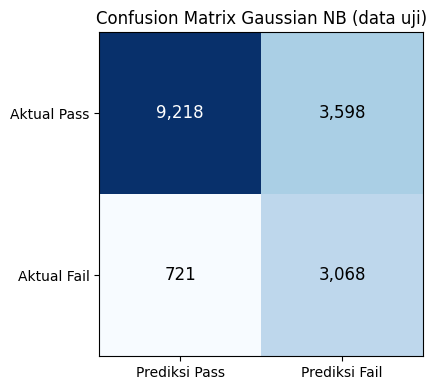

In [30]:
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels([f"Prediksi {KELAS_LAIN}", f"Prediksi {KELAS_POSITIF}"])
ax.set_yticks([0, 1]); ax.set_yticklabels([f"Aktual {KELAS_LAIN}", f"Aktual {KELAS_POSITIF}"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax.set_title("Confusion Matrix Gaussian NB (data uji)")
plt.tight_layout()
plt.show()

9.218 siswa: sebenarnya Pass dan diprediksi Pass → prediksi benar.



3.598 siswa: sebenarnya Pass, tetapi diprediksi Fail → prediksi salah.



721 siswa: sebenarnya Fail, tetapi diprediksi Pass → prediksi salah.



3.068 siswa: sebenarnya Fail dan diprediksi Fail → prediksi benar.

### 7.5 Pemeriksaan overfitting: data latih vs data uji
Selisih besar (latih jauh lebih tinggi dari uji) menandakan overfitting; kedua nilai rendah menandakan underfitting.
Catatan: data latih sudah di-oversampling (50:50) sedangkan data uji tidak (distribusi asli), sehingga **F1 dan recall Fail** lebih tepat dibandingkan daripada accuracy.

In [31]:
pred_latih  = model.predict(X_train)
skor_latih  = model.predict_proba(X_train)[:, idx_pos]
banding = pd.DataFrame([
    evaluasi(y_train, pred_latih, skor_latih, "Data latih"),
    evaluasi(y_test,  y_pred,    skor_fail,  "Data uji"),
]).set_index("Model")
banding[["Accuracy", "Precision (Fail)", "Recall (Fail)", "F1 (Fail)", "ROC-AUC"]].round(4)

,Accuracy,Precision (Fail),Recall (Fail),F1 (Fail),ROC-AUC
Model,,,,,
Data latih,0.7722,0.7476,0.8217,0.7829,0.8543
Data uji,0.7399,0.4602,0.8097,0.5869,0.8488


Interpretasi. Pemeriksaan overfitting dilakukan dengan membandingkan performa model Gaussian Naive Bayes pada data latih dan data uji. Hasil menunjukkan bahwa Recall (Fail) dan ROC-AUC( area dibawah curve) memiliki selisih relatif kecil, masing-masing sebesar 0,0120 dan 0,0055. Hal ini mengindikasikan bahwa kemampuan model dalam mengenali kelas Fail dan membedakan kedua kelas relatif konsisten pada kedua kelompok data. Meskipun Precision (Fail) dan F1 (Fail) mengalami penurunan, perbedaan proporsi kelas akibat oversampling pada data latih dapat memengaruhi kedua metrik tersebut. Oleh karena itu, hasil evaluasi belum menunjukkan indikasi kuat terjadinya overfitting. Namun, kestabilan beberapa metrik tidak membuktikan secara mutlak bahwa overfitting tidak terjadi.

### 7.6 Contoh prediksi beberapa siswa uji

In [32]:
contoh = X_test.sample(8, random_state=RANDOM_STATE)
p_contoh = model.predict_proba(contoh)

tabel_contoh = contoh[["previous_exam_score", "previous_gpa", "study_hours_per_day",
                       "practice_tests_completed", "exam_difficulty"]].copy()
tabel_contoh["Aktual"]   = y_test.loc[contoh.index]
tabel_contoh["Prediksi"] = model.predict(contoh)
tabel_contoh["P(Fail)"]  = p_contoh[:, idx_pos].round(3)
tabel_contoh["P(Pass)"]  = p_contoh[:, 1 - idx_pos].round(3)
tabel_contoh["Benar?"]   = np.where(tabel_contoh["Aktual"] == tabel_contoh["Prediksi"], "benar", "salah")
tabel_contoh

,previous_exam_score,previous_gpa,study_hours_per_day,practice_tests_completed,exam_difficulty,Aktual,Prediksi,P(Fail),P(Pass),Benar?
index_asli,,,,,,,,,,
16088,76.28,3.31,2.50,6,2,Pass,Pass,0.093,0.907,benar
67012,44.83,1.74,4.40,5,1,Pass,Pass,0.288,0.712,benar
82986,68.37,2.79,1.26,6,2,Pass,Fail,0.851,0.149,salah
40509,93.44,3.63,1.30,7,3,Pass,Pass,0.128,0.872,benar
5373,70.92,2.64,3.62,5,2,Pass,Pass,0.365,0.635,benar
75707,78.23,3.18,3.49,4,1,Pass,Pass,0.091,0.909,benar
68071,89.60,3.67,1.58,4,3,Pass,Pass,0.004,0.996,benar
2676,65.58,2.65,0.67,1,3,Fail,Fail,0.930,0.070,benar


In [33]:
# Contoh perhitungan Gaussian Naive Bayes untuk SATU siswa uji (diambil dari baris pertama contoh 7.6)
siswa   = contoh.iloc[0]
id_sis  = contoh.index[0]
x       = siswa[FITUR].astype(float).values
kelas   = list(model.classes_)
prior   = dict(zip(kelas, model.class_prior_))

def log_gauss(x, mu, var):
    """ln N(x | mu, var) = -0.5*ln(2*pi*var) - (x-mu)^2 / (2*var)"""
    return -0.5 * np.log(2 * np.pi * var) - (x - mu) ** 2 / (2 * var)

ll = {k: log_gauss(x, model.theta_[i], varians[i]) for i, k in enumerate(kelas)}   # log-likelihood tiap fitur
tot = {k: np.log(prior[k]) + ll[k].sum() for k in kelas}                          # ln P(k) + sum ln P(x|k)

# posterior = softmax dari skor log (dikurangi nilai terbesar agar stabil)
mx = max(tot.values())
unn = {k: np.exp(tot[k] - mx) for k in kelas}
post = {k: unn[k] / sum(unn.values()) for k in kelas}

# cocokkan dengan predict_proba milik sklearn
p_sk = model.predict_proba(contoh.iloc[[0]])[0]
assert np.allclose([post[k] for k in model.classes_], p_sk), "Hitung manual tidak cocok dengan sklearn"

baris_md = "\n".join(
    f"| {f} | {x[j]:.3f} | {model.theta_[kelas.index(KELAS_POSITIF)][j]:.3f} | {varians[kelas.index(KELAS_POSITIF)][j]:.3f} | {ll[KELAS_POSITIF][j]:.3f}"
    f" | {model.theta_[kelas.index(KELAS_LAIN)][j]:.3f} | {varians[kelas.index(KELAS_LAIN)][j]:.3f} | {ll[KELAS_LAIN][j]:.3f} |"
    for j, f in enumerate(FITUR)
)

display(Markdown(f"""
#### Contoh perhitungan Gaussian Naive Bayes untuk siswa dengan index_asli = {id_sis}

**Rumus:** untuk tiap kelas *k*, skor = ln P(k) + &sum; ln N(x<sub>j</sub> | &mu;<sub>jk</sub>, &sigma;<sup>2</sup><sub>jk</sub>), dengan
ln N(x | &mu;, &sigma;<sup>2</sup>) = -0,5 &middot; ln(2&pi;&sigma;<sup>2</sup>) - (x - &mu;)<sup>2</sup> / (2&sigma;<sup>2</sup>).

| Fitur | Nilai x | &mu; Fail | &sigma;<sup>2</sup> Fail | ln N Fail | &mu; Pass | &sigma;<sup>2</sup> Pass | ln N Pass |
|---|---|---|---|---|---|---|---|
{baris_md}

**Prior:** P({KELAS_POSITIF}) = {prior[KELAS_POSITIF]:.4f}, P({KELAS_LAIN}) = {prior[KELAS_LAIN]:.4f}

**Skor {KELAS_POSITIF}** = ln({prior[KELAS_POSITIF]:.4f}) + {ll[KELAS_POSITIF].sum():.3f} = **{tot[KELAS_POSITIF]:.3f}**

**Skor {KELAS_LAIN}** = ln({prior[KELAS_LAIN]:.4f}) + {ll[KELAS_LAIN].sum():.3f} = **{tot[KELAS_LAIN]:.3f}**

**Peluang akhir** (softmax dari skor):
P({KELAS_POSITIF} | x) = **{post[KELAS_POSITIF]:.4f}**, P({KELAS_LAIN} | x) = **{post[KELAS_LAIN]:.4f}**

**Prediksi:** {max(post, key=post.get)} (kelas dengan skor tertinggi). Aktual: **{y_test.loc[id_sis]}**.
Hasil hitung manual ini cocok dengan `predict_proba` sklearn.
"""))


#### Contoh perhitungan Gaussian Naive Bayes untuk siswa dengan index_asli = 16088

**Rumus:** untuk tiap kelas *k*, skor = ln P(k) + &sum; ln N(x<sub>j</sub> | &mu;<sub>jk</sub>, &sigma;<sup>2</sup><sub>jk</sub>), dengan
ln N(x | &mu;, &sigma;<sup>2</sup>) = -0,5 &middot; ln(2&pi;&sigma;<sup>2</sup>) - (x - &mu;)<sup>2</sup> / (2&sigma;<sup>2</sup>).

| Fitur | Nilai x | &mu; Fail | &sigma;<sup>2</sup> Fail | ln N Fail | &mu; Pass | &sigma;<sup>2</sup> Pass | ln N Pass |
|---|---|---|---|---|---|---|---|
| previous_exam_score | 76.280 | 61.851 | 104.733 | -4.239 | 71.776 | 115.081 | -3.380 |
| previous_gpa | 3.310 | 2.474 | 0.191 | -1.918 | 2.870 | 0.205 | -0.599 |
| attendance_percentage | 92.180 | 82.880 | 63.449 | -3.676 | 85.163 | 61.148 | -3.378 |
| assignment_completion_rate | 96.940 | 66.640 | 135.123 | -6.769 | 70.682 | 146.251 | -5.769 |
| study_hours_per_day | 2.500 | 2.284 | 1.581 | -1.163 | 3.167 | 2.749 | -1.506 |
| self_study_hours | 2.170 | 1.604 | 0.862 | -1.031 | 2.204 | 1.438 | -1.101 |
| practice_tests_completed | 6.000 | 4.555 | 4.540 | -1.905 | 5.742 | 5.839 | -1.807 |
| exam_preparation_days | 3.000 | 12.879 | 82.139 | -3.717 | 16.289 | 69.864 | -4.306 |
| sleep_hours | 7.770 | 6.733 | 1.399 | -1.472 | 7.070 | 1.420 | -1.267 |
| stress_level | 10.000 | 9.593 | 0.740 | -0.880 | 9.312 | 1.274 | -1.226 |
| exam_anxiety_level | 10.000 | 9.152 | 1.348 | -1.335 | 8.867 | 1.951 | -1.582 |
| exam_difficulty | 2.000 | 2.321 | 0.430 | -0.617 | 1.909 | 0.479 | -0.560 |
| family_income | 3.000 | 2.504 | 1.426 | -1.183 | 2.762 | 1.509 | -1.144 |

**Prior:** P(Fail) = 0.5000, P(Pass) = 0.5000

**Skor Fail** = ln(0.5000) + -29.904 = **-30.597**

**Skor Pass** = ln(0.5000) + -27.624 = **-28.317**

**Peluang akhir** (softmax dari skor):
P(Fail | x) = **0.0928**, P(Pass | x) = **0.9072**

**Prediksi:** Pass (kelas dengan skor tertinggi). Aktual: **Pass**.
Hasil hitung manual ini cocok dengan `predict_proba` sklearn.


In [44]:
# ================================================================
# CONTOH PERHITUNGAN LENGKAP GAUSSIAN NAÏVE BAYES — 1 SISWA
# Menampilkan SELURUH alur dari nilai fitur → P(Fail) dan P(Pass)
# ================================================================

# --- Ambil 1 siswa ---
contoh_idx = X_test.index[0]
siswa      = X_test.loc[contoh_idx]
label_asli = y_test.loc[contoh_idx]
kelas_list = list(model.classes_)   # ['Fail', 'Pass']
varians    = model.var_ if hasattr(model, "var_") else model.sigma_

# ================================================================
print("=" * 70)
print("STEP 1 — DATA SISWA YANG AKAN DIPREDIKSI")
print("=" * 70)
print(f"  index_asli : {contoh_idx}  |  label asli : {label_asli}\n")
display(siswa.rename("Nilai Siswa").to_frame().T.round(4))

# ================================================================
print("\n" + "=" * 70)
print("STEP 2 — PRIOR: P(Fail) dan P(Pass)")
print("  Sumber: proporsi kelas pada data latih (sudah oversampling 50:50)")
print("=" * 70)
log_prior = np.log(model.class_prior_)
df_prior  = pd.DataFrame({
    "Jumlah data latih" : (model.class_prior_ * len(X_train)).astype(int),
    "P(kelas)"          : model.class_prior_.round(6),
    "log P(kelas)"      : log_prior.round(6),
}, index=kelas_list)
display(df_prior)

# ================================================================
print("\n" + "=" * 70)
print("STEP 3 — LIKELIHOOD PER FITUR: log P(xi | kelas)")
print("  Rumus Gaussian:")
print("    log P(x|μ,σ) = -0.5·log(2π·σ²) - (x−μ)²/(2·σ²)")
print("=" * 70)

rows       = []
log_ll     = {k: 0.0 for k in kelas_list}   # akumulasi log-likelihood
for j, fitur in enumerate(FITUR):
    x   = float(siswa[fitur])
    row = {"Fitur": fitur, "x (nilai)": round(x, 4)}
    for k_idx, kelas in enumerate(kelas_list):
        mu      = model.theta_[k_idx, j]
        sigma2  = varians[k_idx, j]
        sigma   = np.sqrt(sigma2)
        term1   = -0.5 * np.log(2 * np.pi * sigma2)   # konstanta
        term2   = -((x - mu) ** 2) / (2 * sigma2)      # eksponensial
        ll      = term1 + term2
        log_ll[kelas] += ll
        row[f"μ_{kelas}"]        = round(mu, 4)
        row[f"σ_{kelas}"]        = round(sigma, 4)
        row[f"−(x−μ)²/2σ²|{kelas}"] = round(term2, 4)
        row[f"logP(x|{kelas})"]  = round(ll, 4)
    rows.append(row)

df_ll = pd.DataFrame(rows).set_index("Fitur")
display(df_ll)

# ================================================================
print("\n" + "=" * 70)
print("STEP 4 — SKOR LOG POSTERIOR TIAP KELAS")
print("  Rumus: log_score(kelas) = log P(kelas) + Σ log P(xi|kelas)")
print("=" * 70)
log_scores = np.array([log_prior[k_idx] + log_ll[kelas]
                       for k_idx, kelas in enumerate(kelas_list)])
df_skor = pd.DataFrame({
    "log P(kelas)"        : [round(log_prior[i], 6) for i in range(len(kelas_list))],
    "Σ log P(xi|kelas)"   : [round(log_ll[k], 6) for k in kelas_list],
    "LOG SCORE TOTAL"     : [round(log_scores[i], 6) for i in range(len(kelas_list))],
}, index=kelas_list)
display(df_skor)

# ================================================================
print("\n" + "=" * 70)
print("STEP 5 — KONVERSI KE PROBABILITAS (Softmax)")
print("  Rumus:")
print("    exp_score(kelas)  = exp(log_score(kelas))")
print("    P(kelas | x)      = exp_score(kelas) / Σ exp_score(semua kelas)")
print("=" * 70)
exp_scores  = np.exp(log_scores - log_scores.max())   # stabilisasi numerik
proba_manual = exp_scores / exp_scores.sum()
proba_model  = model.predict_proba(X_test.loc[[contoh_idx]])[0]

df_proba = pd.DataFrame({
    "LOG SCORE"           : log_scores.round(6),
    "exp(log_score)"      : exp_scores.round(10),
    "P(kelas|x) manual"   : proba_manual.round(6),
    "P(kelas|x) model"    : proba_model.round(6),
    "Selisih"             : (proba_manual - proba_model).round(8),
}, index=kelas_list)
display(df_proba)

# ================================================================
print("\n" + "=" * 70)
print("STEP 6 — KEPUTUSAN PREDIKSI")
print("  → Pilih kelas dengan P(kelas|x) TERBESAR")
print("=" * 70)
pemenang_idx   = np.argmax(proba_manual)
prediksi_manual = kelas_list[pemenang_idx]
prediksi_model  = model.predict(X_test.loc[[contoh_idx]])[0]

df_keputusan = pd.DataFrame({
    "Probabilitas (%)"  : (proba_manual * 100).round(2),
    "Prediksi?"         : ["✅ DIPILIH" if k == prediksi_manual else "—" for k in kelas_list],
}, index=kelas_list)
display(df_keputusan)

print(f"\n  ╔══════════════════════════════════════════╗")
print(f"  ║  Prediksi manual   : {prediksi_manual:<20}║")
print(f"  ║  Prediksi model    : {prediksi_model:<20}║  ← {'✅ sama' if prediksi_manual == prediksi_model else '❌ beda!'}")
print(f"  ║  Label asli        : {label_asli:<20}║  ← {'✅ benar' if prediksi_manual == label_asli else '❌ salah'}")
print(f"  ╚══════════════════════════════════════════╝")


STEP 1 — DATA SISWA YANG AKAN DIPREDIKSI
  index_asli : 2546  |  label asli : Fail



,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,practice_tests_completed,exam_preparation_days,sleep_hours,stress_level,exam_anxiety_level,exam_difficulty,family_income
Nilai Siswa,83.38,3.45,77.92,76.64,0.89,0.55,4.0,23.0,5.1,10.0,10.0,2.0,1.0



STEP 2 — PRIOR: P(Fail) dan P(Pass)
  Sumber: proporsi kelas pada data latih (sudah oversampling 50:50)


,Jumlah data latih,P(kelas),log P(kelas)
Fail,51456,0.5,-0.693147
Pass,51456,0.5,-0.693147



STEP 3 — LIKELIHOOD PER FITUR: log P(xi | kelas)
  Rumus Gaussian:
    log P(x|μ,σ) = -0.5·log(2π·σ²) - (x−μ)²/(2·σ²)


,x (nilai),μ_Fail,σ_Fail,−(x−μ)²/2σ²|Fail,logP(x|Fail),μ_Pass,σ_Pass,−(x−μ)²/2σ²|Pass,logP(x|Pass)
Fitur,,,,,,,,,
previous_exam_score,83.38,61.8513,10.2339,-2.2127,-5.4573,71.7755,10.7276,-0.5851,-3.8768
previous_gpa,3.45,2.4744,0.4373,-2.4892,-2.5809,2.8697,0.4533,-0.8193,-0.9470
attendance_percentage,77.92,82.8804,7.9655,-0.1939,-3.1880,85.1627,7.8197,-0.4289,-3.4045
assignment_completion_rate,76.64,66.6401,11.6242,-0.3700,-3.7421,70.6822,12.0934,-0.1213,-3.5329
study_hours_per_day,0.89,2.2838,1.2575,-0.6142,-1.7623,3.1673,1.6581,-0.9432,-2.3678
self_study_hours,0.55,1.6039,0.9287,-0.6440,-1.4889,2.2037,1.1993,-0.9507,-2.0514
practice_tests_completed,4.00,4.5553,2.1307,-0.0340,-1.7094,5.7418,2.4164,-0.2598,-2.0610
exam_preparation_days,23.00,12.8793,9.0631,-0.6235,-3.7467,16.2887,8.3584,-0.3224,-3.3646
sleep_hours,5.10,6.7325,1.1829,-0.9524,-2.0393,7.0699,1.1918,-1.3661,-2.4605


... (3 outputs left out)

,LOG SCORE,exp(log_score),P(kelas|x) manual,P(kelas|x) model,Selisih
Fail,-31.129111,0.427844,0.299643,0.299643,0.0
Pass,-30.280115,1.000000,0.700357,0.700357,-0.0



STEP 6 — KEPUTUSAN PREDIKSI
  → Pilih kelas dengan P(kelas|x) TERBESAR


,Probabilitas (%),Prediksi?
Fail,29.96,—
Pass,70.04,✅ DIPILIH



  ╔══════════════════════════════════════════╗
  ║  Prediksi manual   : Pass                ║
  ║  Prediksi model    : Pass                ║  ← ✅ sama
  ║  Label asli        : Fail                ║  ← ❌ salah
  ╚══════════════════════════════════════════╝


### 7.9 Ringkasan hasil untuk laporan

In [37]:
ringkasan_model = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (Fail)", "Recall (Fail)", "F1 (Fail)",
               "Precision (Pass)", "Recall (Pass)", "F1 (Pass)", "ROC-AUC"],
    "Data uji":   [hasil_utama[k] for k in ["Accuracy", "Precision (Fail)", "Recall (Fail)", "F1 (Fail)",
                                            "Precision (Pass)", "Recall (Pass)", "F1 (Pass)", "ROC-AUC"]],
}).set_index("Metrik")
ringkasan_model["Data uji"] = ringkasan_model["Data uji"].round(4)
display(ringkasan_model)
print(f"Pembanding accuracy (tebak Pass semua): {(y_test == KELAS_LAIN).mean():.4f}")

,Data uji
Metrik,
Accuracy,0.7399
Precision (Fail),0.4602
Recall (Fail),0.8097
F1 (Fail),0.5869
Precision (Pass),0.9275
Recall (Pass),0.7193
F1 (Pass),0.8102
ROC-AUC,0.8488


Pembanding accuracy (tebak Pass semua): 0.7718


Kesimpulan. Model Gaussian Naïve Bayes dengan 13 fitur mampu mengenali 80,97% siswa yang tidak lulus berdasarkan nilai Recall (Fail), dengan ROC-AUC sebesar 0,8488. Hasil evaluasi menunjukkan bahwa performa model relatif konsisten pada data latih dan data uji, sehingga tidak ditemukan indikasi kuat terjadinya overfitting. Analisis pendukung juga menunjukkan bahwa penggunaan prior kelas memengaruhi keseimbangan antara precision dan recall, sedangkan penskalaan fitur tidak mengubah hasil prediksi. Namun, Precision (Fail) yang hanya sebesar 46,02% menunjukkan bahwa masih banyak siswa yang diprediksi tidak lulus padahal sebenarnya lulus. Selain itu, accuracy sebesar 73,99% masih berada di bawah baseline prediksi seluruh siswa lulus sebesar 77,18%. Oleh karena itu, model ini memiliki potensi sebagai alat bantu identifikasi siswa yang berisiko tidak lulus, tetapi hasil prediksinya perlu ditafsirkan secara hati-hati karena keterbatasan asumsi model dan karakteristik dataset semi-sintetis.